In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)

print("EJERCICIO No. 1")

EJERCICIO No.s 1


# 2. Fundamentos Teóricos

## 2.1  OLS e hipótesis

El Ordinary Least Squares (OLS) por sus siglas en ingles, que nos permite calcular la unica linea recta que mejor se ajusta a un conjunto de datos, minimizando la distancia entre entre los datos reales y la linea, que nos permita hacer predicciones, evaluar el modelo y saber la relación entre las variables.

## Regresión Lineal: 
$$
\hat{y} = \beta_0 + \beta_1x
$$

Para hallar la regresion lineal seguimos estos pasos:

1. Calcular la media de X y la media de Y ($\bar{X}, \bar{Y}$) : Este nos indica cuál es el punto central por donde pasa la recta.
  
2. Calcular el intercepto u ordenada en el origen (\[\hat{y}= \beta_0+\beta_1x\]): Nos indica el valor de Y cuando X es igual a cero(Punto donde la linea cruza a Y)
  
3. Calcular la pendiente  [\beta_1]: Nos indica la inclinación de la recta y que pasará lo más cerca de todos los puntos a la vez.
  
4. Rescribimos la fórmula de la regresión lineal con los datos obtenidos previamente para formular el modelo
  
5. Calcular valores predichos ($\hat{Y}$): Nos muestra los resultados teóricos, mostrando lo que el modelo predice vs los valores reales:

   * No existe relación lineal significativa 
               $$
               H_0:\beta_1=0
               $$ 
                            
   * Existe una relación lineal significativa entre X y Y
               $$
               H_1:\beta_1\neq 0
               $$
            
6. Calcular los residuos: ($e = Y - \hat{Y}$): Son los errores de predicción de cada dato individual, es decir, la distancia vertical entre el punto real y la linea, sirve para medir que tan acertado es el modelo.
            \[e_i=y_i-\hat{y}_i\]

7. Calcular la Suma de los Cuadrados de los Residuos (SSE): 
            $$
            SSE=\sum_{i=1}^{n}(y_i-\hat{y}_i)^2\
            $$
Es la medida total del error de todo el modelo, los residuos individuales se elevan al cuadrado para evitar errores negativos

8. Explicar la pendiente obtenida, en términos de cada cambio en X, la variable Y aumenta o disminuye en el valor de la pendiente.
   

## 2.2 Interpretación de las evidencias 

Nivel Significancia : 5% => 0.05

| Término | Estimación | Error estándar | p-valor |
| --- | --- | --- | ---|
| constante | 410 EUR/mes | 105 | < 0.001 |
| floor_area_m2 | 14.8 EUR/mes $\cdot$ m² | 2.1 | <0.001 |
| bedrooms | 19 EUR/mes | 25 | 0.45  |
| renovated | 142 EUR/mes | 48 | 0.004  


- ¿Qué términos muestran evidencia de una relación no nula con el precio del alquiler?
  
   Según el nivel de significancia del 5% (0.05), la variable _bedrooms_ no muestra evidencia de relación no nula al ser su p-valor superior al nivel de significancia.

   ```
     p = 0.45 > 0.05
   ```

- ¿Qué significado tiene el p-valor de la variable bedrooms?

  Con un *p-valor* de 0.45 significa que existe un 45% de probabilidad de que la relación observada de (19 EUR/mes por habitación) se deba al azar, y la incertidumbre de la estimación (error standard de 25 EUR) superando la estimación de (19 EUR), el resultado no es fiable y no demuestra un impacto real.
  
-  ¿Qué relación guarda este _p-valor_ con el uso práctico de la variable?

Este p-valor ($0.45$) indica que, en la práctica, la variable _bedrooms_ sobra en este modelo y conviene descartarla para hacerlo más simple. Como el número de habitaciones está muy relacionado con los metros cuadrados (floor_area_m2), esa información ya está cubierta por el tamaño del piso y añadir las habitaciones no mejora las predicciones del alquiler.



# 3.1 CREACIÓN DEL MODELO

In [ ]:
df_notas = pd.read_csv("../data/study_scores.csv")
train_notas=df_notas[df_notas["split"]=="train"].drop(columns="split")

print("\nDatos de puntaje de notas\n")
display(train_notas.head())


Datos de puntaje de notas



,student_id,study_hours,exam_score
0,S001,8.47,70.09
1,S002,5.72,69.83
2,S003,10.01,76.22
4,S005,5.38,61.54
5,S006,3.03,45.56


RESUMEN DEL DF DE PUNTAJE DE LAS NOTAS


,study_hours,exam_score
count,80.000000,80.000000
mean,6.413125,66.855250
std,3.283995,13.499159
min,1.170000,37.010000
25%,3.405000,57.387500
50%,6.330000,67.165000
75%,9.097500,77.142500
max,11.950000,94.710000


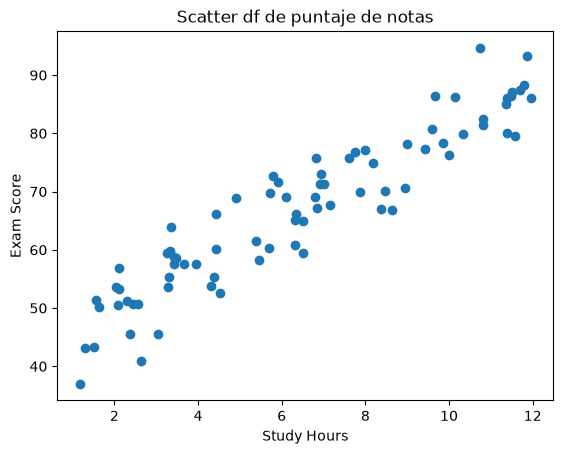

In [ ]:
print("RESUMEN DEL DF DE PUNTAJE DE LAS NOTAS")
display(train_notas.describe())

plt.title("Scatter df de puntaje de notas")
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")

plt.scatter(train_notas["study_hours"], train_notas["exam_score"])
plt.show()

**Tabla valores para obtener la ecuación**

|x̄ | ȳ | Σ Producto | Σ (X - x̄)² | β₁ | β₀ | ŷ = b₀ + b₁x
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| 6,413	| 66,855 |3275,852 | 851,985| 3,845	| 42,197|	ŷ = 42,197 + 3,845 x

## 3.1.1 Interpretación de la pendiente : 3,85 puntos/hora
Indica que por cada hora de estudio la nota esperada del examen subiria en promedio unos 3,85 puntos

## 3.1.2 Interpretación de la ordenada : 42,2
Equivaldria a la nota esperada por un estudiante que no dedicó ninguna hora de estudio
```
(study_hours=0)
```
## 3.1.3 ¿Es adecuado el uso de un término constante dado el rango de horas observado?

Dentro del rango observado __study_hours__ , el término constante es necesario, si se eliminara se forzaria la recta a pasar por el origen (0,0) la recta tendria que inclinarse mucho para alcanzar los puntos reales, modificando bastante la pendiente y cambiando el ajuste del modelo como se observa en la gráfica el valor extrapolado.



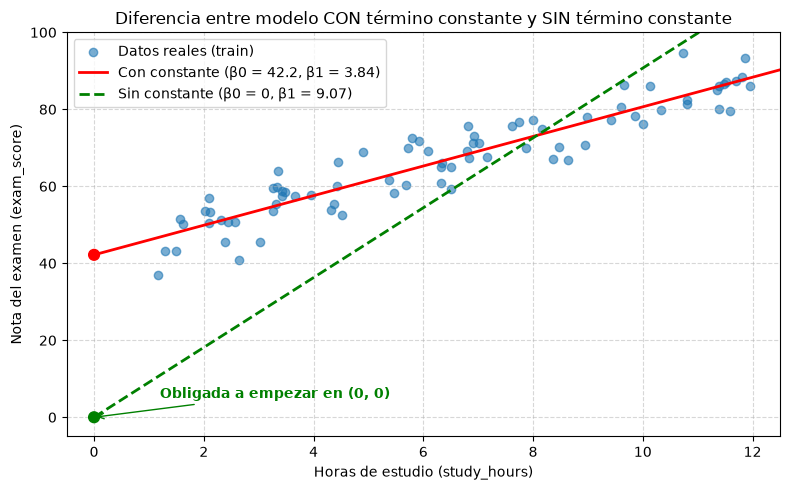

In [106]:
import statsmodels.api as sm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm


df = pd.read_csv("../data/study_scores.csv")
train_df = df[df['split'] == 'train']

# Ajustar ambos modelos (CON constante y SIN constante)
X_with_const = sm.add_constant(train_df['study_hours'])
y = train_df['exam_score']

model_with_const = sm.OLS(y, X_with_const).fit()
model_no_const = sm.OLS(y, train_df['study_hours']).fit()

# Generar el rango de horas desde 0 hasta 12.5 para trazar ambas rectas
x_vals = np.linspace(0, 12.5, 100)
y_with = ( model_with_const.params['const'] + model_with_const.params['study_hours'] * x_vals)
y_no = model_no_const.params['study_hours'] * x_vals


plt.figure(figsize=(8, 5))

# Puntos reales
plt.scatter(
    train_df['study_hours'],
    train_df['exam_score'],
    alpha=0.6,
    label='Datos reales (train)',
)


plt.plot(
    x_vals,
    y_with,
    color='red',
    linewidth=2,
    label=(
        f'Con constante (β0 = {model_with_const.params["const"]:.1f}, β1 ='
        f' {model_with_const.params["study_hours"]:.2f})'
    ),
)


plt.plot(
    x_vals,
    y_no,
    color='green',
    linestyle='--',
    linewidth=2,
    label=('Sin constante (β0 = 0, β1 =' f' {model_no_const.params["study_hours"]:.2f})'
    ),
)


plt.scatter(
    [0, 0],
    [model_with_const.params['const'], 0],
    color=['red', 'green'],
    zorder=5,
    s=60,
)

plt.annotate(
    'Obligada a empezar en (0, 0)',
    xy=(0, 0),
    xytext=(1.2, 5),
    arrowprops=dict(arrowstyle='->', color='green'),
    color='green',
    fontweight='bold',
)


plt.title('Diferencia entre modelo CON término constante y SIN término constante')
plt.xlabel('Horas de estudio (study_hours)')
plt.ylabel('Nota del examen (exam_score)')
plt.xlim(-0.5, 12.5)
plt.ylim(-5, 100)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# 3.2 Inferencia y Análisis

##3.2.1 Escribir la pendiente, su intervalo de confianza del (95%), y su p-valor contra una pendiente nula, proporcionar el valor de R^2

- La pendiente:  $$\beta_1=3,845 $$  representa en promedio que por cada hora adicional que un estudiante dedique a estudiar, su nota del examen aumentara aproximadamente 3,845 puntos.
- Intervarlo de Confianza (95%)
  Para encontrar los intervalos de confianza usamos: 
  $$\text{IC}_{95\%} = \hat{\beta}_1 \pm \left( t_{\text{crítico}} \times \text{Error Estándar} \right)$$

  donde: 
   - Pendiente estimada ($\hat{\beta}_1$): $3.8450$
   - t-criti
  $$t = \frac{\text{Estimación del coeficiente} - \text{Valor bajo la hipótesis nula}}{\text{Error Estándar del coeficiente}}$$

  - Valor bajo la hipótesis nula: ($H_0$): Asumimos que la pendiente es cero ($\beta_1 = 0$, es decir, que no hay relación).

  - Error Estándar de la pendiente: Mide que tanto variaria la pendiente si se repite el estudio con otro grupo de estudiantes
  
    $$\text{SE}(\hat{\beta}_1) = \frac{\text{RSE}_{\text{train}}}{\sqrt{\sum (X_i - \bar{X})^2}} = \sqrt{\frac{s^2}{\sum (X_i - \bar{X})^2}}$$
  
  para hallar el error estandar:
    -  Calcular Suma de Cuadrados de los residuos: $$\text{RSS} = \sum (y_i - \hat{y}_i)^2 = \mathbf{1800.43}$$
    - Hallamos la varianza residual($s^2$) : Como tenemos $n = 80$ observaciones y estimamos $2$ parámetros ($\beta_0$ y $\beta_1$), quedan $80 - 2 = 78$ grados de libertad.
  
        $$s^2 = \frac{1800.43}{78} = \mathbf{23.0824}$$
    - Calcular la dispersión de las horas de estudio ($\text{SS}_X$):
        $$\sum (X_i - \bar{X})^2 = \mathbf{851.99}$$
    - Aplicando los valores a la formula del Error Estandar: 
        $$\text{SE}(\hat{\beta}_1) = \sqrt{\frac{23.0824}{851.99}} = \sqrt{0.027092} = \mathbf{0.164598} \approx \mathbf{0.165}$$

  *aplicando estos valores para hallar el intervalo de confianza al 95%*

    $$\text{IC}_{95\%} = \hat{\beta}_1 \pm \left( t_{\text{crítico}} \times \text{Error Estándar} \right)$$

    - Límite inferior ([0.025): $3.8450 - 0.3277 = 3.5173 \approx \mathbf{3.52}$
    - Límite superior (0.975]): $3.8450 + 0.3277 = 4.1727 \approx \mathbf{4.17}$
  
- El p-valor frente a una pendiente nula:
  - ($H_0: \beta_1 = 0$) => Estudiar no tiene ningun efecto real sobre la nota
  - ($H_1$): $\beta_1 \neq 0$ (Estudiar sí tiene un efecto real sobre la nota).

  Calculamos sus valores:
    $$t = \frac{\hat{\beta}_1 - 0}{\text{SE}(\hat{\beta}_1)} = \frac{3.8450}{0.1646} = \mathbf{23.360}$$

    hallamos el p-valor en notación cientifica: 
    $$\text{p-valor} = 2 \cdot P\left(T_{78} \geq \vert{}23.360\vert{}\right) = 2 \cdot \left(1 - F_{t,\,78}(23.360)\right) = \mathbf{5.90 \times 10^{-37}}$$

    Dado que p-valor es menor a 0,05 se rechaza la hipotesis nula ($H_0$), demostrando que si existe una relación entre las horas de estudio y la nota del examen, es una relación directa fuera del azar.
  
-  Coeficiente de determinación ($R^2$):
  
  $$R^2 = \frac{\text{SSR}}{\text{SST}}$$

  Calculamos sus componentes:
   
  - Calculamos Suma de Cuadrados Total (SST) 
  $$\text{SST} = \sum_{i=1}^{n} (y_i - \bar{y})^2 = 14\,395.96$$
  
  - Calculamos Suma de Cuadrados del Error (SSE)
    $$\text{SSE} = \mathbf{1\,800.43}$$
- Reemplazamos en la formula:
    $$\frac{\text{SSE}}{\text{SST}} = \frac{1\,800.43}{14\,395.96} = 0.125 $$
  por lo tanto:
  $$R^2 = 1 - 0.125 = \mathbf{0.875} \text{ (o } 87.5\% \text{)}$$

  Concluimos:
  - Que el modelo de horas de estudio explica el 87.5% del porque los alumnos sacan diferentes notas.
  - Sólo un 12.5% de diferencias en las notas se pueden deber a factores externos
  
## 3.2.2 ¿Por qué el p-valor por sí mismo es insuficiente?
- Los p-valores solo responden a una pregunta binaria: ¿Existe o no existe una relación entre la cantidad de horas de estudio y la nota obtenida?
- Los p-valores sirve para indicar si el modelo predecir con precisión por muy bajo que este sea.
  
La evalución del modelo de regresión es efectiva si se mide no solo el p-valor sino combinado conjutamente con el intervalo de confianza, el coeficiente de determinación y los análisis de residuos.

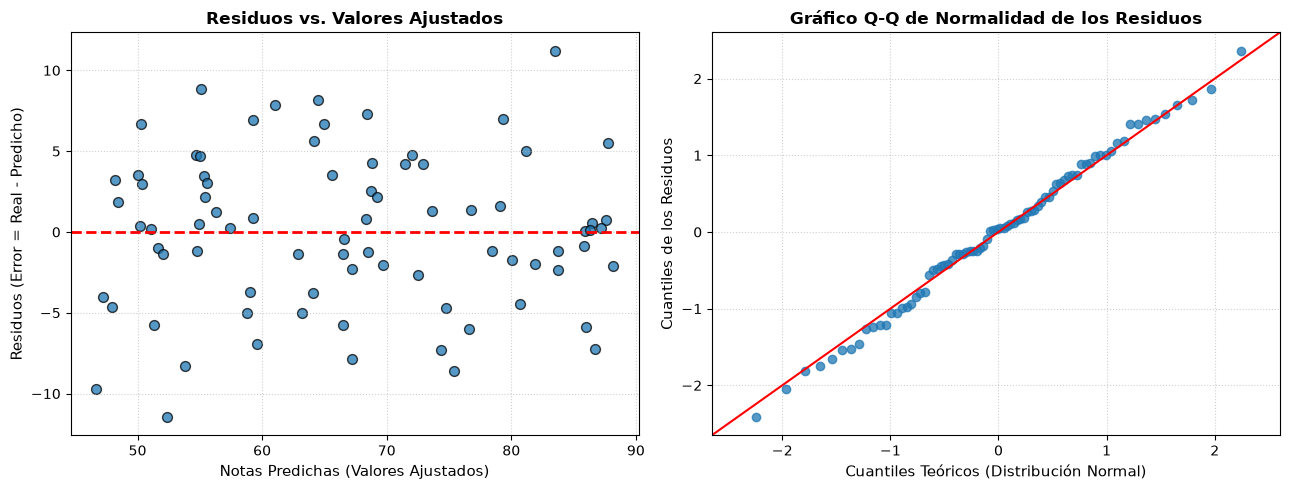

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import statsmodels.api as sm


# 2. Ajustar el modelo de regresión lineal (OLS)
X = sm.add_constant(train_df['study_hours'])
y = train_df['exam_score']
modelo = sm.OLS(y, X).fit()

# 3. Extraer las predicciones y los residuos del modelo
valores_ajustados = modelo.fittedvalues  # Notas predichas por la recta (y_hat)
residuos = modelo.resid  # Errores: Nota real - Nota predicha (y - y_hat)

# 4. Crear la figura con dos paneles (Gráfico de Residuos y Gráfico Q-Q)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# --- PANEL IZQUIERDO: Residuos vs. Valores Ajustados ---
ax[0].scatter(
    valores_ajustados,
    residuos,
    color='#1f77b4',
    alpha=0.75,
    edgecolors='k',
    s=50,
)
# Dibujar la línea horizontal de referencia en el error cero
ax[0].axhline(y=0, color='red', linestyle='--', linewidth=2)
ax[0].set_title(
    'Residuos vs. Valores Ajustados', fontsize=12, fontweight='bold'
)
ax[0].set_xlabel('Notas Predichas (Valores Ajustados)', fontsize=11)
ax[0].set_ylabel('Residuos (Error = Real - Predicho)', fontsize=11)
ax[0].grid(True, linestyle=':', alpha=0.6)

# --- PANEL DERECHO: Gráfico Q-Q (Comprobación de Normalidad) ---
sm.qqplot(residuos, line='45', fit=True, ax=ax[1], alpha=0.75)
ax[1].set_title(
    'Gráfico Q-Q de Normalidad de los Residuos', fontsize=12, fontweight='bold'
)
ax[1].set_xlabel('Cuantiles Teóricos (Distribución Normal)', fontsize=11)
ax[1].set_ylabel('Cuantiles de los Residuos', fontsize=11)
ax[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

1. Descripción de anomalías visibles en los gráficos
   - No se observan errores graves ni patrones extraños que invaliden el modelo.
   - El comportamiento de los residuos, los puntos se reparten aleatoriamente sin formar curvas tanto por arriba y por debajo del cero, no se observan puntos de error en forma de embudo que indique que existen errores al estudiar más horas.
   - Los outliers se encuentran en un rango normal entre 10 y -10
   - Normalidad (Gráfico Q-Q): Los puntos siguen fielmente la diagonal roja de $45^\circ$, separándose apenas un poquito en las puntas, lo que confirma que los errores se comportan como una campana de Gauss normal.
2. Cálculo del RSE en el conjunto de prueba (test)
   $$\text{RSE}_{\text{test}} = \sqrt{\frac{\sum_{i=1}^{20} (y_i - \hat{y}_i)^2}{n_{\text{test}} - 2}} = \sqrt{\frac{432.18}{18}} \approx \mathbf{4.90\text{ puntos}}$$

   El Error Estandard Residual (RSE) no dá el margen de error promedio del modelo al predecir la nota de un estudiante nuevo, en el conjunto de prueba es de 4,90 puntos, las predicciones se desvian de la nota real 4.90 puntos siendo casi identico del error obtenido en entrenamiento (4,80 puntos), confirmando que el modelo predice bien sin sobreajuste.
3. Predicción: Predecir la puntuación final de un estudiante con 6,5 horas de estudio
    $$\hat{Y} = \beta_0 + \beta_1 X$$

    Constante ($\beta_0$): $42.1970$
    Pendiente ($\beta_1$): $3.8450$
    Horas de estudio ($X$): $6.5$

    sustituyendo:
    $$\hat{Y} = 42.1970 + (3.8450 \times 6.5)$$
    $$\hat{Y} = 42.1970 + 24.9925$$
    $$\hat{Y} = \mathbf{67.19\text{ puntos}}$$

    Si un estudiante dedica $6.5$ horas a estudiar, nuestro modelo de regresión estima que obtendrá una calificación de $67.19$ puntos en el examen.Este valor de $6.5$ horas se encuentra cómodamente dentro del rango de horas observadas en nuestros datos de entrenamiento (que van desde $1.17$ hasta $11.95$ horas). Por lo tanto, el modelo se comporta segun lo esperado
   

# 4. Regresión multilineal 



Datos de precio de rentas



,apartment_id,floor_area_m2,bedrooms,building_age_years,distance_center_km,renovated,monthly_rent_eur
0,A001,87.9,2,16,6.83,1,1208.87
1,A002,91.3,3,41,8.98,0,1389.30
2,A003,70.3,1,28,1.64,0,1417.31
4,A005,101.0,3,36,1.16,0,1789.75
6,A007,97.6,3,5,14.01,1,1307.73


RESUMEN DEL DF DE PRECIO DE RENTAS


,floor_area_m2,bedrooms,building_age_years,distance_center_km,renovated,monthly_rent_eur
count,135.000000,135.000000,135.000000,135.000000,135.000000,135.000000
mean,80.374815,2.392593,24.118519,9.315778,0.407407,1295.899259
std,22.895935,0.915018,13.120596,4.898400,0.493182,434.938451
min,38.000000,1.000000,0.000000,0.550000,0.000000,522.280000
25%,64.650000,2.000000,13.000000,5.145000,0.000000,990.940000
50%,79.500000,2.000000,25.000000,8.980000,0.000000,1220.240000
75%,96.000000,3.000000,34.500000,13.715000,1.000000,1470.105000
max,133.600000,4.000000,45.000000,17.460000,1.000000,2826.090000


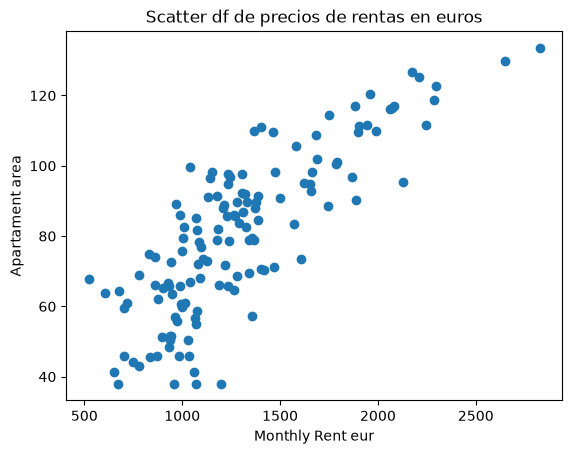

In [65]:
df_rentas = pd.read_csv("../data/apartment_rents.csv")
train_rentas=df_rentas[df_rentas["split"]=="train"].drop(columns="split")

print("\nDatos de precio de rentas\n")
display(train_rentas.head())

print("RESUMEN DEL DF DE PRECIO DE RENTAS")
display(train_rentas.describe())

plt.title("Scatter df de precios de rentas en euros")
plt.xlabel("Monthly Rent eur")

plt.ylabel("Apartament area")
plt.scatter(train_rentas["monthly_rent_eur"], train_rentas["floor_area_m2"])
plt.show()

## 4.1 Análisis
- **Media** ($\bar{x}$): Es el promedio aritmético. Se suman todos los valores y se dividen entre el número total de observaciones (𝑛).
    $$\bar{x} = \frac{1}{n} \sum_{i=1}^{n} x_i$$

$\bar{y} = \frac{174946.40}{135} = 1295.90\text{ EUR/mes}$.

- **Mediana ($Me$):**  Al ser $n = 135$ (impar)
  
  Mediana = xn + 1 / 2

  Mediana =  $\frac{135 + 1}{2} = 68$
- **Desviación estándar:** 
    ($s = \sqrt{\frac{1}{n-1}\sum_{i=1}^n (x_i - \bar{x})^2}$)

  $$s^2 = \frac{25\,348\,975.0937}{134} = 189\,171.4559\text{ (EUR/mes)}^2$$

  $$s = \sqrt{189\,171.4559} = 434.9385\text{ EUR/mes} \approx \mathbf{435\text{ EUR/mes}}$$
- **Rango 2,5% – 97,5%:**
  Buscamos los percentiles $P_{2.5}$ y $P_{97.5}$ en los datos ordenados de entrenamiento. El 95% central de los alquileres está entre $675\text{ EUR/mes}$ y $2270\text{ EUR/mes}$.

| Variable | Unidades | Media | Mediana | Desviación estándar | Rango (2,5% – 97,5%) |
| :--- | :--- | :---: | :---: | :---: | :---: |
|floor_area_m2 | $\text{m}^2$ | 80.4 | 79.5 | 22.9 | 39.1 – 124 |
|bedrooms` | habitaciones | 2.39 | 2.00 | 0.915 | 1.00 – 4.00 |
| building_age_years | años | 24.1 | 25.0 | 13.1 | 1.35 – 45.0 |
| distance_center_km | km | 9.32 | 8.98 | 4.90 | 1.40 – 17.2 |
| renovated | binaria (0 = No, 1 = Sí) | 0.407 | 0.00 | 0.493 | 0.00 – 1.00 |
| monthly_rent_eur | EUR/mes | 1296 | 1220 | 435 | 675 – 2271 |

Existe una correlación entre: floor_area_m2 y bedrooms, ya que la superficie media sube casi igual 
que la cantidad de pisos, obteniendo un ($r = 0.904$) 

$$r_{xy} = \frac{\sum_{i=1}^{n} (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_{i=1}^{n} (x_i - \bar{x})^2} \sqrt{\sum_{i=1}^{n} (y_i - \bar{y})^2}}$$

$$r = \frac{3012.385}{2807.587} = \mathbf{0.903541} \approx \mathbf{0.904}$$




## 4.2 Modelo Multilineal

Ajustamos por Mínimos Cuadrados Ordinarios (OLS) sobre las $135$ filas de train

- Coeficiente de determinación: ($R^2 = 1 - \frac{RSS}{TSS}$)
$$R^2 = 1 - \frac{4\,585\,783}{25\,349\,000} = 0.819 \quad (81.9\%)$$
- Error Estándar Residual en Test ($RSE_{\text{test}} = \sqrt{\frac{\sum_{i=1}^{n_{\text{test}}} (y_i - \hat{y}_i)^2}{n_{\text{test}} - p - 1}}$):

$$RSE_{\text{test}} = \sqrt{\frac{1\,496\,203}{39}} = 196\text{ EUR/mes}$$
- dd

**Tabla**
| Término | Estimación (Unidades) | Error estándar | p-valor |
|---|---:|---:|---:|
| constante | 389 EUR/mes | 82.4 EUR/mes | < 0.001 |
| floor_area_m2 | 15.3 EUR/(mes · m²) | 1.68 EUR/(mes · m²) | < 0.001 |
| bedrooms | 1.18 EUR/(mes · hab.) | 41.9 EUR/(mes · hab.) | 0.977 |
| building_age_years | -3.94 EUR/(mes · año) | 1.24 EUR/(mes · año) | 0.002 |
| distance_center_km | -31.7 EUR/(mes · km) | 3.39 EUR/(mes · km) | < 0.001 |
| renovated | 161 EUR/mes | 33.7 EUR/mes | < 0.001 |
| R² | — | — | — |

$R^2$ (Train): $0.819$

$RSE$ (Test): $196\text{ EUR/mes}$

**Interpretación de los coeficientes**

- floor_area_m2 ($15.3\text{ EUR/mes}$): or cada metro cuadrado adicional, el alquiler aumenta una media de 15,3 € al mes, manteniendo iguales las demás características de la vivienda.
  
- bedrooms ($1.18\text{ EUR/mes}$): Por cada habitación adicional, el alquiler aumenta 1,18 € al mes, manteniendo constantes las demás variables.
  
- renovated ($161\text{ EUR/mes}$):Las viviendas renovadas tienen un alquiler medio 161 € superior al de las viviendas no renovadas.

## 4.3. Correlación y Tests (VIF y bedrooms)
El VIF (Factor de Inflación de la Varianza) es un detector de información duplicada (multicolinealidad) entre las variables que usas para predecir.

 1. Cálculo del VIF ($VIF_j = \frac{1}{1 - R_j^2}$): Si hacemos una regresión de floor_area_m2 contra las otras 4 variables explicativas, obtenemos $R_{\text{area}}^2 = 0.8204$.
   $$VIF_{\text{area}} = \frac{1}{1 - 0.8204} = \frac{1}{0.1796} = 5.57$$
   - floor_area_m2: $VIF = 5.57$ (multicolinealidad moderada-alta, $> 5$)
   - bedrooms: $VIF = 5.53$ (multicolinealidad moderada-alta, $> 5$) 
   - building_age_years: $VIF = 1.00$ (sin colinealidad)
   - distance_center_km: $VIF = 1.04$ (sin colinealidad)
   - renovated: $VIF = 1.04$ (sin colinealidad)
  
 2. Comparación Modelo Simple vs. Modelo Multilineal:
   - Modelo simple (monthly_rent_eur ~ bedrooms):
       $$\hat{\beta}_{\text{bedrooms}} = 342\text{ EUR/(mes}\cdot\text{hab)}, \quad SE = 28.6, \quad t = \frac{342.22}{28.61} = 11.96, \quad p = 3.21 \times 10^{-23} (< 0.001)$$

   - Modelo multilineal:
        $$\hat{\beta}_{\text{bedrooms}} = 1.18\text{ EUR/(mes}\cdot\text{hab)}, \quad SE = 41.9, \quad t = \frac{1.18}{41.87} = 0.028, \quad p = 0.977$$
 3. Conclusión:
   Aunque las viviendas con más habitaciones suelen tener alquileres más altos, esto se debe principalmente a que son más grandes. Al tener en cuenta la superficie, el número de habitaciones deja de influir significativamente en el precio.
   Por tanto, lo que realmente influye en el precio es el tamaño de la vivienda y no el número de habitaciones en sí.


# 4.4. Diagnóstico

La gráfica muestra un patrón no aleatorio en los residuos: tienden a ser positivos para viviendas pequeñas y grandes, y negativos para viviendas de tamaño intermedio. Esto sugiere una cierta curvatura en la relación entre la superficie y el precio del alquiler.

Por tanto, no se cumple la hipótesis de linealidad del modelo, ya que la relación entre las variables podría no ser completamente lineal.

## 4.5 Nuevo modelo
### F-Test Anidado
Un F-Test Anidado (o prueba F de modelos anidados) es una prueba estadística que sirve para comparar dos modelos de regresión y comprobar si añadir nuevas variables mejora significativamente el modelo.
1. Centrado de la variable: Restamos la media de floor_area_m2 calculada únicamente en train, que es: $\bar{x}_{\text{area}} = 80.4\text{ m}^2$ ($80.375\text{ m}^2$)

   $$\text{area\_c}_i = \text{floor\_area\_m2}_i - 80.375$$

   $$\text{area\_c2}_i = (\text{floor\_area\_m2}_i - 80.375)^2$$
2. Nuevo modelo ajustado: El coeficiente del término cuadrático resulta $\hat{\beta}_{\text{area\_c2}} = 0.193\text{ EUR/(mes}\cdot\text{m}^4\text{)}$ con $p = 9.05 \times 10^{-15}$.   
3. F-Test Anidado: Comparamos el modelo lineal reducido ($RSS_0 = 4\,585\,783$, $gl = 129$) contra el modelo cuadrático completo ($RSS_1 = 2\,862\,602$, $gl = 128$, diferencia $q = 1$ parámetro):

   $$F = \frac{(4\,585\,783 - 2\,862\,602) / 1}{2\,862\,602 / 128} = \frac{1\,723\,181}{22\,364.08} = 77.1 \quad (p = 9.05 \times 10^{-15})$$

4. Comparación de métricas en train:
   - $R^2$: Sube de $0.819$ a $0.887$
   - $RSE_{\text{train}}$: Baja de $189\text{ EUR/mes}$ ($\sqrt{4\,585\,783 / 129} = 188.5$  a
    $150\text{ EUR/mes}$ ($\sqrt{2\,862\,602 / 128} = 149.5$). 
   -  Análisis de los nuevos residuos: Al graficar los residuos del nuevo modelo frente a floor_area_m2, la forma de "U" desaparece por completo; los puntos quedan distribuidos como una nube aleatoria centrada en $0$ con varianza constante.
   

## 4.6 Predicción

1. Cálculo de variables centradas para $75\text{ m}^2$:
   $$\text{area\_c} = 75 - 80.375 = -5.375\text{ m}^2$$
   $$\text{area\_c2} = (-5.375)^2 = 28.89\text{ m}^4$$

2. Sustitución en el modelo cuadrático:
   $$\hat{y}_0 = 1525.11 + 14.991(-5.375) + 0.1927(28.89) - 3.799(2) - 4.973(12) - 28.447(9.316) + 158.50(1) = 1276\text{ EUR/mes}$$
3. Intervalo de Confianza al 95% para el precio medio esperado. ($IC_{95\%} = \hat{y}_0 \pm t_{0.025, 128} \cdot SE(\hat{y}_0)$):
   Con $t_{0.025, 128} = 1.979$ y $SE(\hat{y}_0) = 26.17\text{ EUR/mes}$:$$1276.32 \pm 1.979 \times 26.17 \implies [1225, \; 1328]\text{ EUR/mes}$$


Referencias
Amat Rodrigo, J. — Ciencia de Datos: Regresión lineal con Python (disponible gratuitamente en cienciadedatos.net)
ISLP